In [ ]:
"""
Mehrab Hafiz
ESE 568 - Project 3 - Exercise 2
November 10, 2026
"""

# Download and extract dataset

import matplotlib.pyplot as plt
import numpy as np
import PIL
import tensorflow as tf

from keras import layers, models

import pathlib

dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

data_dir = tf.keras.utils.get_file("flower_photos.tgz", 
    origin=dataset_url, 
    extract=True,
    cache_dir=str("../data/raw")
)

data_dir = pathlib.Path(data_dir).parent / "flower_photos_extracted" / "flower_photos"

Img count: 3670
../data/raw/datasets/flower_photos_extracted/flower_photos
['daisy', 'dandelion', 'LICENSE.txt', 'roses', 'sunflowers', 'tulips']
Here are some roses


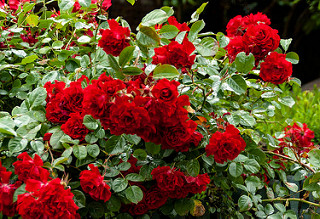

In [25]:
# Initial validations

image_count = len(list(data_dir.glob('*/*.jpg')))
print(f"Img count: {image_count}")


import os
print(data_dir)
print(os.listdir(data_dir))

print("Here are some roses")
roses = list(data_dir.glob('roses/*'))
PIL.Image.open(str(roses[14]))


And some tulips


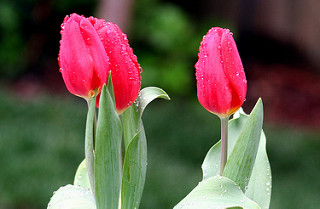

In [27]:
print("And some tulips")
tulips = list(data_dir.glob('tulips/*'))
PIL.Image.open(str(tulips[0]))

In [31]:
# Create dataset
batch_size = 32
img_height = 180
img_width = 180

train_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="training",
  seed=456,
  image_size=(img_height, img_width),
  batch_size=batch_size)

val_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="validation",
  seed=456,
  image_size=(img_height, img_width),
  batch_size=batch_size)

class_names = train_ds.class_names
print(class_names)


Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


image_batch: size=32 height=180 width=180 channels=3
labels_batch: size=32


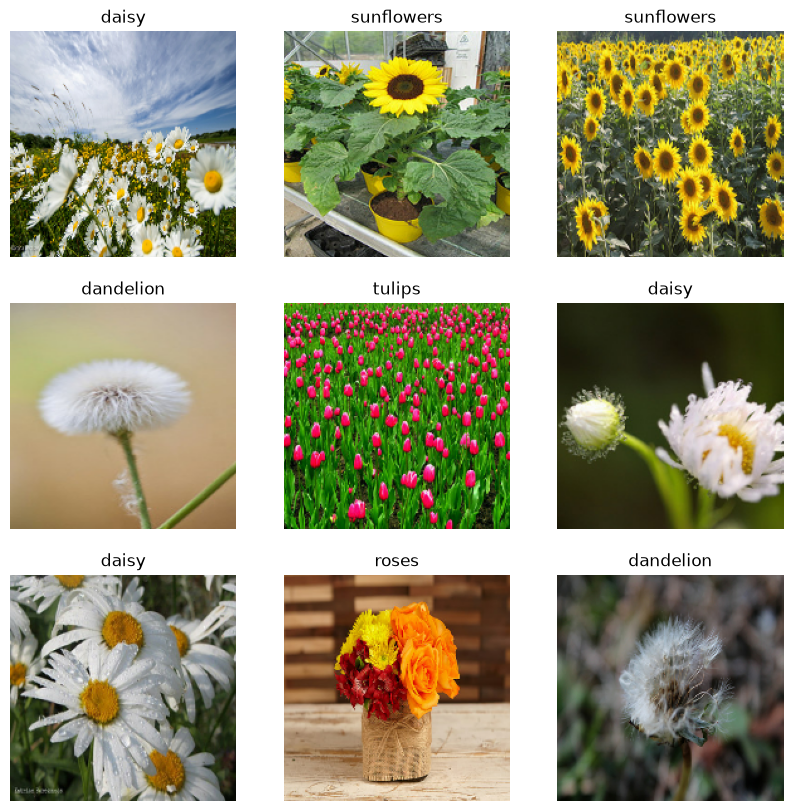

In [35]:
# Visualize dataset 

for image_batch, labels_batch in train_ds:
  print(f"image_batch: size={image_batch.shape[0]} height={image_batch.shape[1]} width={image_batch.shape[2]} channels={image_batch.shape[3]}")
  print(f"labels_batch: size={labels_batch.shape[0]}")
  break

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i]])
    plt.axis("off")

In [59]:
# Standardize the color values for neural nets

normalization_layer = layers.Rescaling(1./255)
normalized_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
image_batch, labels_batch = next(iter(normalized_ds))
first_image = image_batch[0]
# Notice the pixel values are now in `[0,1]`.
print("Dataset normalized")
print(f"min: {np.min(first_image)} max: {np.max(first_image)}")

# A basic Keras model
num_classes = len(class_names)

model1 = models.Sequential([
  layers.Rescaling(1./255, input_shape=(img_height, img_width, 3)),
  layers.Conv2D(16, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(32, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(64, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Flatten(),
  layers.Dense(128, activation='relu'),
  layers.Dense(num_classes)
])

model1.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

model1.summary()

Dataset normalized
min: 0.0 max: 1.0


/mnt/c/Users/mehra/Documents/Class/ESE 568/ESE-568-Project-3---Gen-AI-Image-Recognition/.venv/lib/python3.14/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_14 (Rescaling)        │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 180, 180, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_30 (MaxPooling2D) │ (None, 90, 90, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 90, 90, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_31 (MaxPooling2D) │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_32 (MaxPooling2D) │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_10 (Flatten)            │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │     3,965,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,989,285 (15.22 MB)

 Trainable params: 3,989,285 (15.22 MB)

 Non-trainable params: 0 (0.00 B)

In [60]:
# Train the model for 10 epochs

def train(model, train, val, epochs=10):
  hist = model.fit(
    train,
    validation_data=val,
    epochs=epochs
  )

  return hist

history = train(model1, train_ds, val_ds)

Epoch 1/10


/mnt/c/Users/mehra/Documents/Class/ESE 568/ESE-568-Project-3---Gen-AI-Image-Recognition/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.3927 - loss: 1.4272 - val_accuracy: 0.4550 - val_loss: 1.2282
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5514 - loss: 1.0853 - val_accuracy: 0.6063 - val_loss: 1.0155
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.6529 - loss: 0.9064 - val_accuracy: 0.5913 - val_loss: 1.0095
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7187 - loss: 0.7668 - val_accuracy: 0.6253 - val_loss: 0.9502
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7844 - loss: 0.5661 - val_accuracy: 0.6308 - val_loss: 1.0827
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8655 - loss: 0.4032 - val_accuracy: 0.6240 - val_loss: 1.1150
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9063 - loss: 0.2758 - val_accuracy: 0.6172 - val_loss: 1.2482
Epoch 8/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9452 - loss: 0.1725 - val_accuracy: 0.6240 - val_loss: 1.4877
Ep

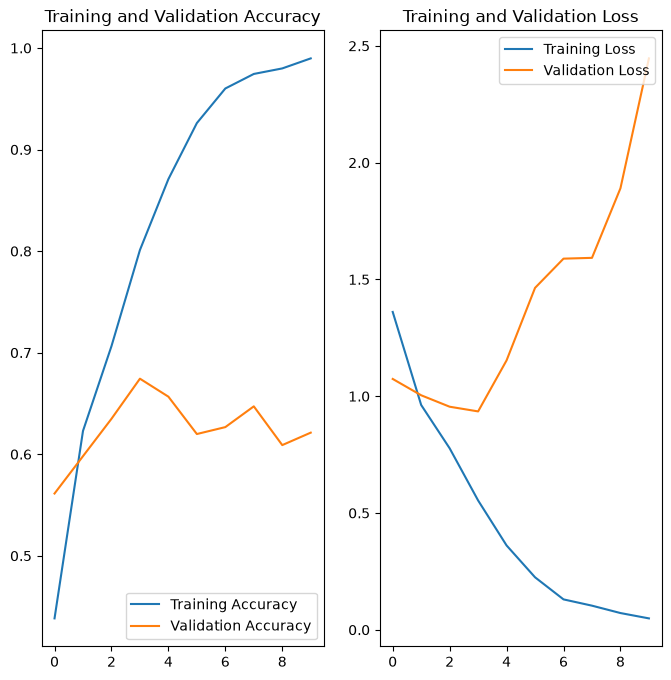

In [49]:
# Model validations

def validate(hist, epochs=10):
    acc = hist.history['accuracy']
    val_acc = hist.history['val_accuracy']

    loss = hist.history['loss']
    val_loss = hist.history['val_loss']

    epochs_range = range(epochs)

    plt.figure(figsize=(8, 8))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title('Training and Validation Accuracy')

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title('Training and Validation Loss')
    plt.show()

validate(history)

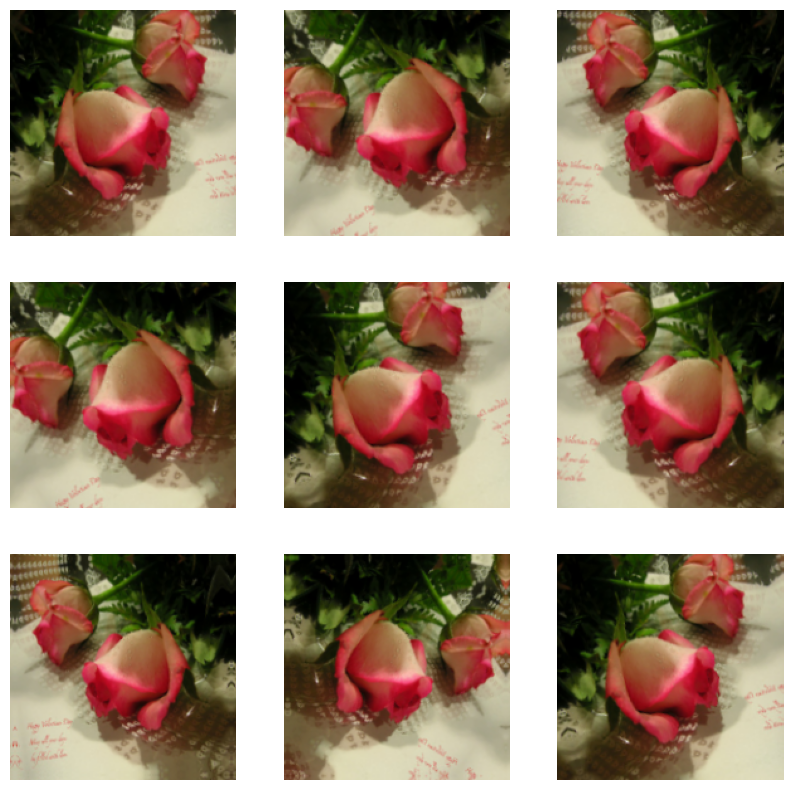

In [63]:
# Accuracy on validation set goes down after epoch 4, demonstrating classic overfitting

from keras import Sequential

# Augment dataset by adding random rotations, flips, random zooms. 
# forces the model to generalize rather than memorizing strict patterns

data_augmentation = Sequential(
  [
    layers.RandomFlip("horizontal",
                      input_shape=(img_height,
                                  img_width,
                                  3)),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
  ]
)

plt.figure(figsize=(10, 10))
for images, _ in train_ds.take(1):
  for i in range(9):
    augmented_images = data_augmentation(images)
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(augmented_images[0].numpy().astype("uint8"))
    plt.axis("off")

Epoch 1/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.4516 - loss: 1.3013 - val_accuracy: 0.4918 - val_loss: 1.1847
Epoch 2/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.6039 - loss: 1.0154 - val_accuracy: 0.6267 - val_loss: 0.9430
Epoch 3/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.6335 - loss: 0.9253 - val_accuracy: 0.6240 - val_loss: 0.9464
Epoch 4/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.6533 - loss: 0.8792 - val_accuracy: 0.6580 - val_loss: 0.8704
Epoch 5/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.6788 - loss: 0.8209 - val_accuracy: 0.6649 - val_loss: 0.8723
Epoch 6/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.6870 - loss: 0.7946 - val_accuracy: 0.6635 - val_loss: 0.8646
Epoch 7/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.7010 - loss: 0.7599 - val_accuracy: 0.7153 - val_loss: 0.7873
Epoch 8/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.7190 - loss: 0.7147 - val_accuracy: 0.7139 - v

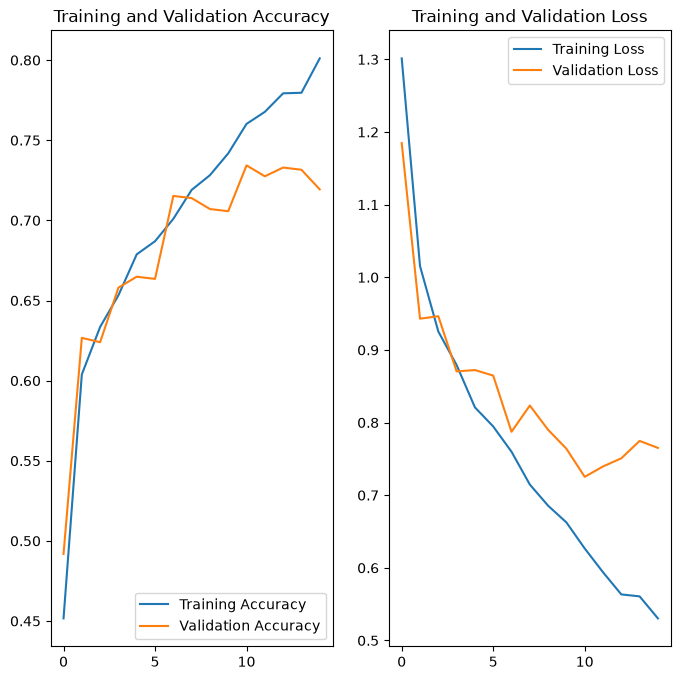

In [70]:
# Train and test using the augmented dataset to see how it performs

model2 = Sequential([
  data_augmentation,
  layers.Rescaling(1./255),
  layers.Conv2D(16, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(32, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(64, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Flatten(),
  layers.Dense(128, activation='relu'),
  layers.Dense(num_classes, name="outputs")
])

model2.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])


history = train(model2, train_ds, val_ds, epochs=15)
validate(history, epochs=15)


Epoch 1/15


E0000 00:00:1794360849.413876   33971 meta_optimizer.cc:996] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape insequential_24/dropout_8/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.4608 - loss: 1.2686 - val_accuracy: 0.5640 - val_loss: 1.0706
Epoch 2/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.6005 - loss: 1.0151 - val_accuracy: 0.6144 - val_loss: 1.0112
Epoch 3/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.6141 - loss: 0.9521 - val_accuracy: 0.6485 - val_loss: 0.8945
Epoch 4/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.6628 - loss: 0.8790 - val_accuracy: 0.6090 - val_loss: 0.9743
Epoch 5/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.6768 - loss: 0.8195 - val_accuracy: 0.6649 - val_loss: 0.8231
Epoch 6/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.7084 - loss: 0.7664 - val_accuracy: 0.7084 - val_loss: 0.7595
Epoch 7/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.7214 - loss: 0.7211 - val_accuracy: 0.6826 - val_loss: 0.7944
Epoch 8/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.7302 - loss: 0.6969 - val_accuracy: 0.6921 - val_loss: 0.

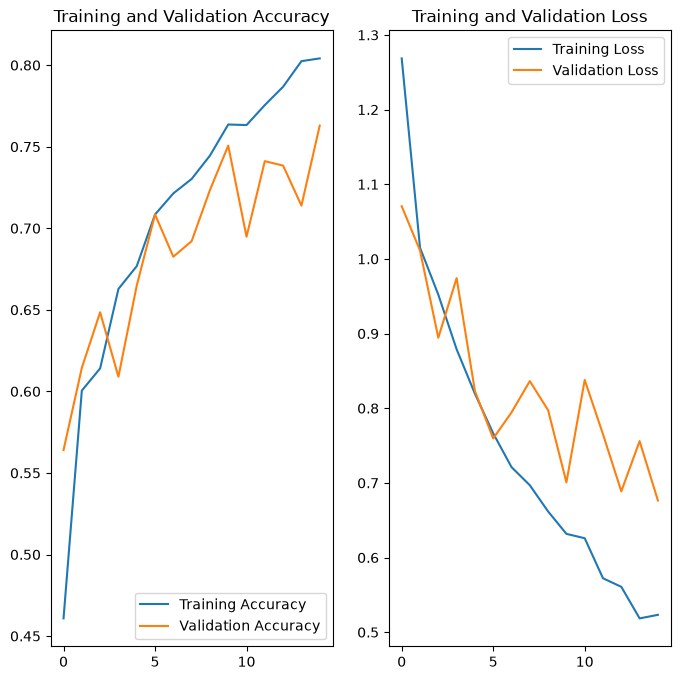

In [71]:
# With the augmented dataset, the model has a modest boost in overall validation accuracy
# Model continues to learn past epoch 3 with no spikes in validation loss in the later epochs

# Add dropout to see if it yields a further boost
model3 = Sequential([
  data_augmentation,
  layers.Rescaling(1./255),
  layers.Conv2D(16, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(32, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(64, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Dropout(0.2),
  layers.Flatten(),
  layers.Dense(128, activation='relu'),
  layers.Dense(num_classes, name="outputs")
])

model3.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

history = train(model3, train_ds, val_ds, epochs=15)
validate(history, epochs=15)


In [72]:
# Adding dropout added a minor performance boost and a more gradual learning

# Final validation on new data
sunflower_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/592px-Red_sunflower.jpg"
sunflower_path = tf.keras.utils.get_file('Red_sunflower', origin=sunflower_url)

img = tf.keras.utils.load_img(
    sunflower_path, target_size=(img_height, img_width)
)
img_array = tf.keras.utils.img_to_array(img)
img_array = tf.expand_dims(img_array, 0) # Create a batch

predictions = model3.predict(img_array)
score = tf.nn.softmax(predictions[0])

print(
    "This image most likely belongs to {} with a {:.2f} percent confidence."
    .format(class_names[np.argmax(score)], 100 * np.max(score))
)

117948/117948 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 325ms/step
This image most likely belongs to sunflowers with a 90.97 percent confidence.
